Section 1 — Imports and configuration

In [9]:
from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

# Project root
PROJECT_ROOT = Path.cwd().parent

# BDDA dataset
BDDA_ROOT = PROJECT_ROOT / "data" / "BDDA"

SPLITS = ["training", "validation", "test"]

MODALITIES = {
    "camera": "camera_videos",
    "gaze": "gazemap_videos",
    "gps": "gps_jsons"
}

REPORT_DIR = PROJECT_ROOT / "reports" / "video_dataset"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("BDDA root:", BDDA_ROOT)

Project root: c:\Users\arijk\Desktop\DriveSight\DriveSight
BDDA root: c:\Users\arijk\Desktop\DriveSight\DriveSight\data\BDDA


Section 2 — Inspect the dataset structure

In [10]:
def inspect_dataset_structure():

    results = []

    for split in SPLITS:

        split_path = BDDA_ROOT / split

        for modality, folder in MODALITIES.items():

            modality_path = split_path / folder

            if modality_path.exists():

                files = list(modality_path.iterdir())

                results.append({
                    "split": split,
                    "modality": modality,
                    "file_count": len([
                        f for f in files if f.is_file()
                    ]),
                    "folder_exists": True
                })

            else:

                results.append({
                    "split": split,
                    "modality": modality,
                    "file_count": 0,
                    "folder_exists": False
                })

    return pd.DataFrame(results)


structure_df = inspect_dataset_structure()

display(structure_df)

,split,modality,file_count,folder_exists
0,training,camera,926,True
1,training,gaze,926,True
2,training,gps,926,True
3,validation,camera,203,True
4,validation,gaze,200,True
5,validation,gps,203,True
6,test,camera,306,True
7,test,gaze,303,True
8,test,gps,306,True


Section 3 — Verify file correspondence

In [11]:

def get_file_ids(folder_path, modality):
    ids = set()

    for file in folder_path.iterdir():
        if not file.is_file():
            continue

        if modality == "camera" and file.suffix.lower() == ".mp4":
            ids.add(file.stem)

        elif modality == "gaze" and file.suffix.lower() == ".mp4":
            video_id = file.stem.replace("_pure_hm", "")
            ids.add(video_id)

        elif modality == "gps" and file.suffix.lower() == ".json":
            ids.add(file.stem)

    return ids


def check_matching_files():
    matching_results = []

    for split in SPLITS:
        camera_dir = BDDA_ROOT / split / MODALITIES["camera"]
        gaze_dir = BDDA_ROOT / split / MODALITIES["gaze"]
        gps_dir = BDDA_ROOT / split / MODALITIES["gps"]

        camera_ids = get_file_ids(camera_dir, "camera")
        gaze_ids = get_file_ids(gaze_dir, "gaze")
        gps_ids = get_file_ids(gps_dir, "gps")

        all_ids = camera_ids | gaze_ids | gps_ids

        sorted_ids = sorted(
            all_ids,
            key=lambda x: (0, int(x)) if x.isdigit() else (1, x)
        )

        for video_id in sorted_ids:
            matching_results.append({
                "split": split,
                "video_id": video_id,
                "camera_exists": video_id in camera_ids,
                "gaze_exists": video_id in gaze_ids,
                "gps_exists": video_id in gps_ids,
                "complete": (
                    video_id in camera_ids
                    and video_id in gaze_ids
                    and video_id in gps_ids
                )
            })

    return pd.DataFrame(matching_results)


matching_df = check_matching_files()

display(matching_df.head(10))

print("Total sequences:", len(matching_df))
print("Complete sequences:", matching_df["complete"].sum())
print("Incomplete sequences:", (~matching_df["complete"]).sum())


,split,video_id,camera_exists,gaze_exists,gps_exists,complete
0,training,2,True,True,True,True
1,training,3,True,True,True,True
2,training,4,True,True,True,True
3,training,5,True,True,True,True
4,training,10,True,True,True,True
5,training,11,True,True,True,True
6,training,12,True,True,True,True
7,training,13,True,True,True,True
8,training,15,True,True,True,True
9,training,17,True,True,True,True


Total sequences: 1435
Complete sequences: 1429
Incomplete sequences: 6


Section 4 — Identifier les vidéos sans Gaze

In [ ]:

missing_gaze = matching_df[
    matching_df["camera_exists"] &
    ~matching_df["gaze_exists"]
]

display(missing_gaze)

print("Missing gaze videos:", len(missing_gaze))

,split,video_id,camera_exists,gaze_exists,gps_exists,complete
927,validation,1738,True,False,True,False
928,validation,1739,True,False,True,False
929,validation,1741,True,False,True,False
1129,test,1,True,False,True,False
1300,test,1037,True,False,True,False
1302,test,1045,True,False,True,False


Missing gaze videos: 6


Section 5 — Résumé des correspondances 

In [ ]:

matching_summary = matching_df.groupby("split").agg(
    total_sequences=("video_id", "count"),
    complete_sequences=("complete", "sum"),
    missing_camera=("camera_exists", lambda x: (~x).sum()),
    missing_gaze=("gaze_exists", lambda x: (~x).sum()),
    missing_gps=("gps_exists", lambda x: (~x).sum())
)

display(matching_summary)

,total_sequences,complete_sequences,missing_camera,missing_gaze,missing_gps
split,,,,,
test,306,303,0,3,0
training,926,926,0,0,0
validation,203,200,0,3,0


Section 6 — Extraire les métadonnées des vidéos

In [14]:

def get_video_metadata(video_path):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return {
            "width": None,
            "height": None,
            "fps": None,
            "frame_count": None,
            "duration_sec": None,
            "readable": False
        }

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    duration = frame_count / fps if fps > 0 else None

    cap.release()

    return {
        "width": width,
        "height": height,
        "fps": fps,
        "frame_count": frame_count,
        "duration_sec": duration,
        "readable": True
    }


# Select 10 complete training videos
sample_sequences = matching_df[
    (matching_df["split"] == "training") &
    (matching_df["complete"])
].head(10)

video_metadata = []

for _, row in sample_sequences.iterrows():
    video_id = row["video_id"]
    split = row["split"]

    camera_path = (
        BDDA_ROOT / split / MODALITIES["camera"] / f"{video_id}.mp4"
    )

    gaze_path = (
        BDDA_ROOT / split / MODALITIES["gaze"] /
        f"{video_id}_pure_hm.mp4"
    )

    for modality, path in [
        ("camera", camera_path),
        ("gaze", gaze_path)
    ]:
        metadata = get_video_metadata(path)

        video_metadata.append({
            "split": split,
            "video_id": video_id,
            "modality": modality,
            **metadata
        })

video_metadata_df = pd.DataFrame(video_metadata)

display(video_metadata_df)


,split,video_id,modality,width,height,fps,frame_count,duration_sec,readable
0,training,2,camera,1280,720,29.97,300,10.010010,True
1,training,2,gaze,1024,768,29.00,292,10.068966,True
2,training,3,camera,1280,720,29.97,300,10.010010,True
3,training,3,gaze,1024,768,29.00,292,10.068966,True
4,training,4,camera,1280,720,29.97,300,10.010010,True
5,training,4,gaze,1024,768,29.00,292,10.068966,True
6,training,5,camera,1280,720,30.00,300,10.000000,True
7,training,5,gaze,1024,768,29.00,292,10.068966,True
8,training,10,camera,1280,720,59.94,600,10.010010,True
9,training,10,gaze,1024,768,29.00,292,10.068966,True


Section 7 — Résumer les caractéristiques

In [15]:
metadata_summary = video_metadata_df.groupby("modality").agg(
    width=("width", "median"),
    height=("height", "median"),
    fps=("fps", "median"),
    frame_count=("frame_count", "median"),
    duration_sec=("duration_sec", "median"),
    readable_videos=("readable", "sum")
)

display(metadata_summary)

,width,height,fps,frame_count,duration_sec,readable_videos
modality,,,,,,
camera,1280.0,720.0,29.985,300.0,10.010010,10
gaze,1024.0,768.0,29.000,292.0,10.068966,10


Section 8 — Visualisation des frames

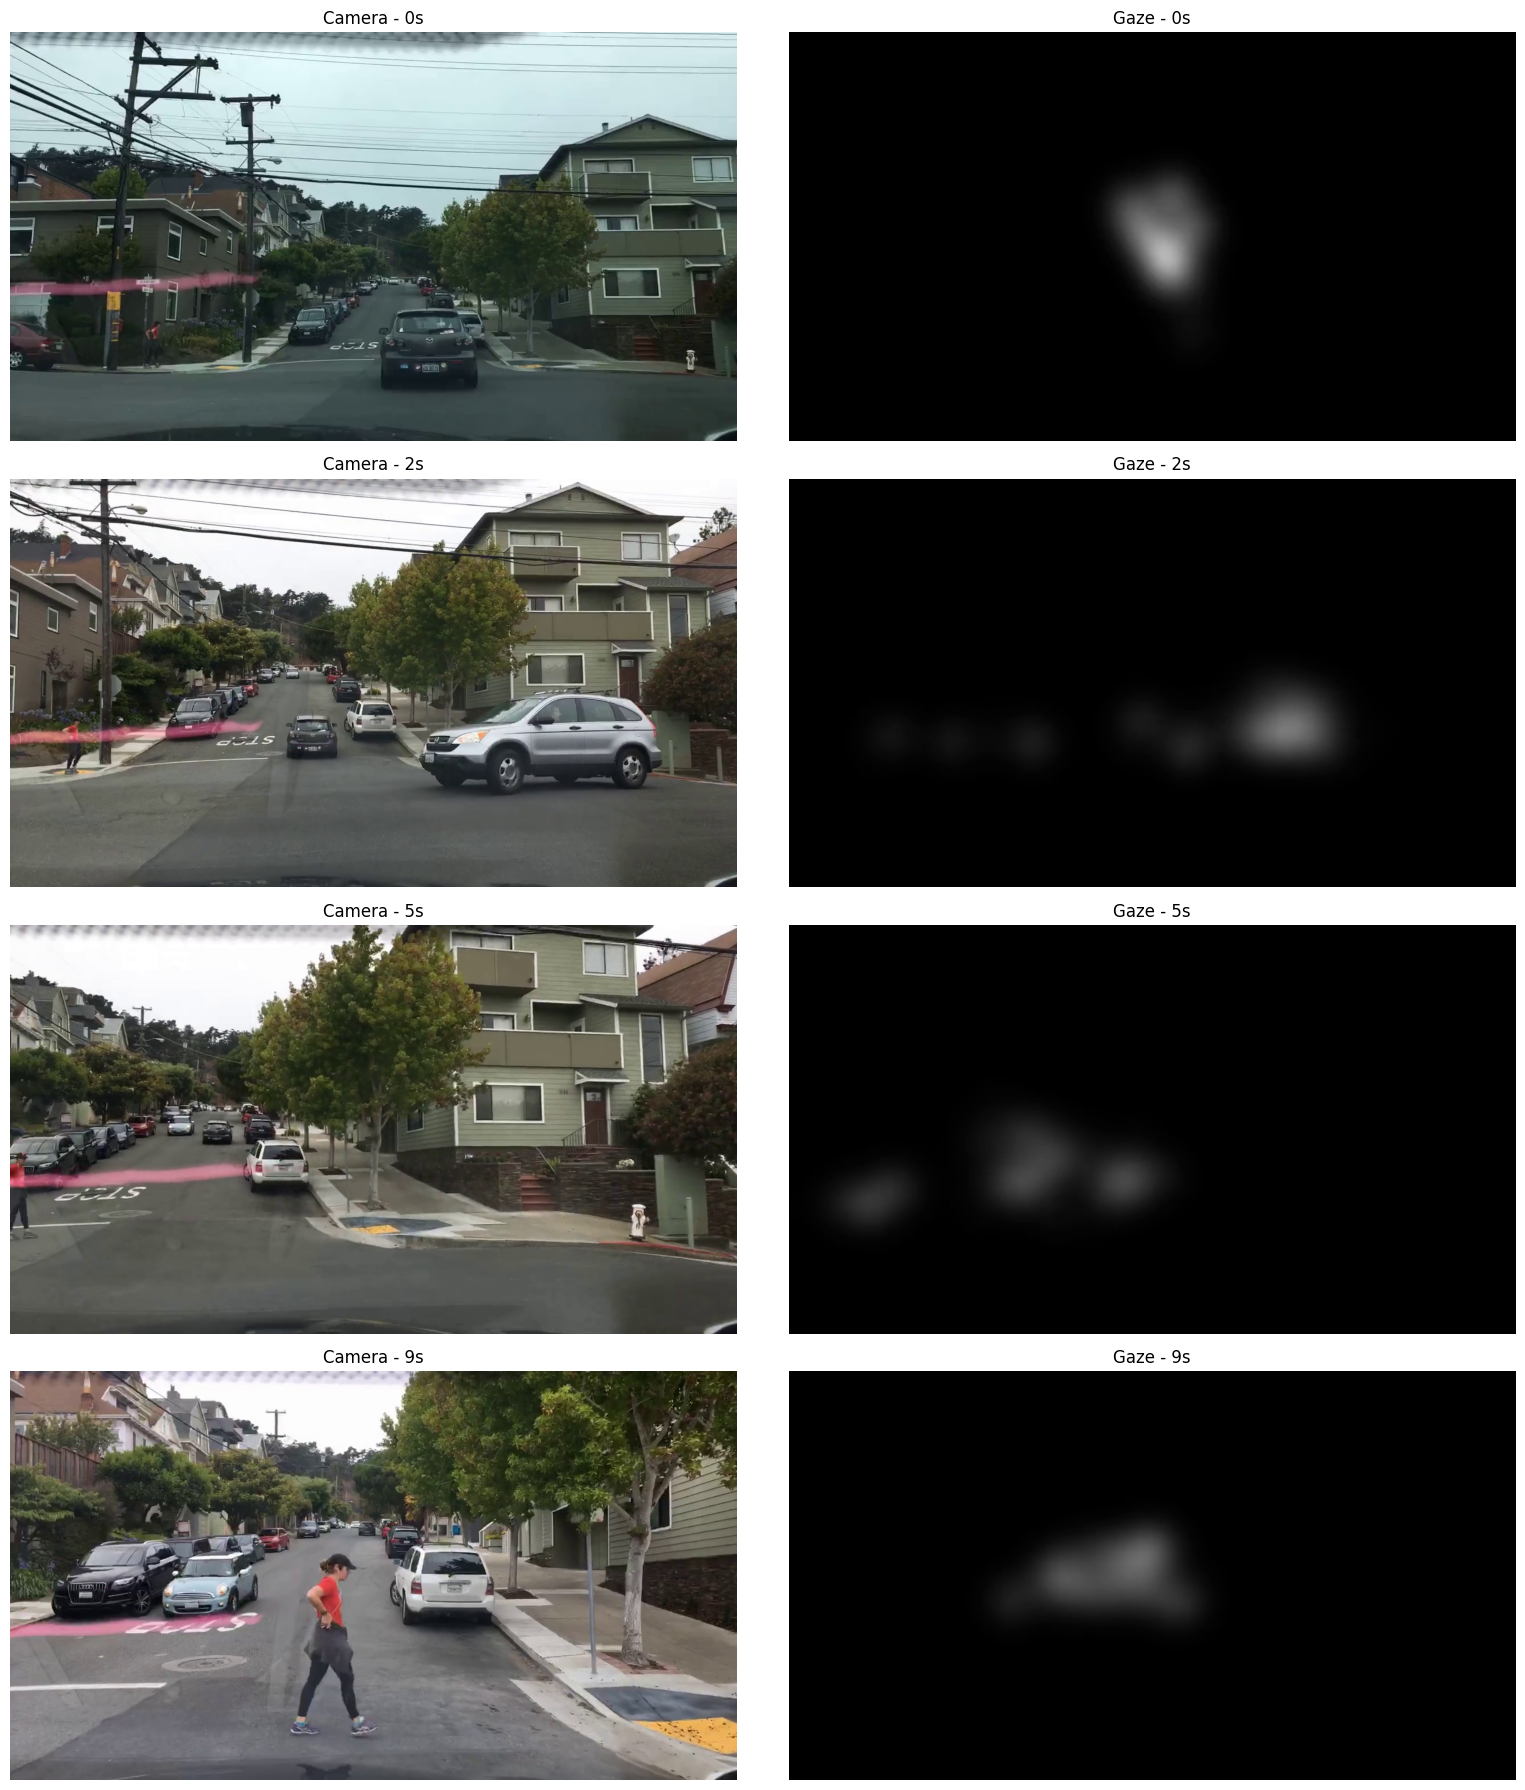

In [16]:

video_id = "2"
split = "training"

camera_path = (
    BDDA_ROOT / split / MODALITIES["camera"] / f"{video_id}.mp4"
)

gaze_path = (
    BDDA_ROOT / split / MODALITIES["gaze"] /
    f"{video_id}_pure_hm.mp4"
)

camera_cap = cv2.VideoCapture(str(camera_path))
gaze_cap = cv2.VideoCapture(str(gaze_path))

camera_fps = camera_cap.get(cv2.CAP_PROP_FPS)
gaze_fps = gaze_cap.get(cv2.CAP_PROP_FPS)

# Compare at the same elapsed times
timestamps = [0, 2, 5, 9]

fig, axes = plt.subplots(
    len(timestamps), 2,
    figsize=(16, 18)
)

for i, t in enumerate(timestamps):

    # Camera frame
    camera_index = round(t * camera_fps)
    camera_cap.set(cv2.CAP_PROP_POS_FRAMES, camera_index)
    ret_cam, camera_frame = camera_cap.read()

    # Gaze frame
    gaze_index = round(t * gaze_fps)
    gaze_cap.set(cv2.CAP_PROP_POS_FRAMES, gaze_index)
    ret_gaze, gaze_frame = gaze_cap.read()

    if ret_cam:
        camera_frame = cv2.cvtColor(
            camera_frame, cv2.COLOR_BGR2RGB
        )
        axes[i, 0].imshow(camera_frame)
        axes[i, 0].set_title(f"Camera - {t}s")
    else:
        axes[i, 0].set_title(f"Camera - unavailable at {t}s")

    if ret_gaze:
        gaze_frame = cv2.cvtColor(
            gaze_frame, cv2.COLOR_BGR2RGB
        )

        # Crop the central 576 pixels vertically
        gaze_crop = gaze_frame[96:672, :, :]

        # Resize to camera dimensions
        gaze_resized = cv2.resize(
            gaze_crop, (1280, 720)
        )

        axes[i, 1].imshow(gaze_resized)
        axes[i, 1].set_title(f"Gaze - {t}s")
    else:
        axes[i, 1].set_title(f"Gaze - unavailable at {t}s")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

camera_cap.release()
gaze_cap.release()

plt.tight_layout()
plt.show()


Section 9 — Gaze overlay

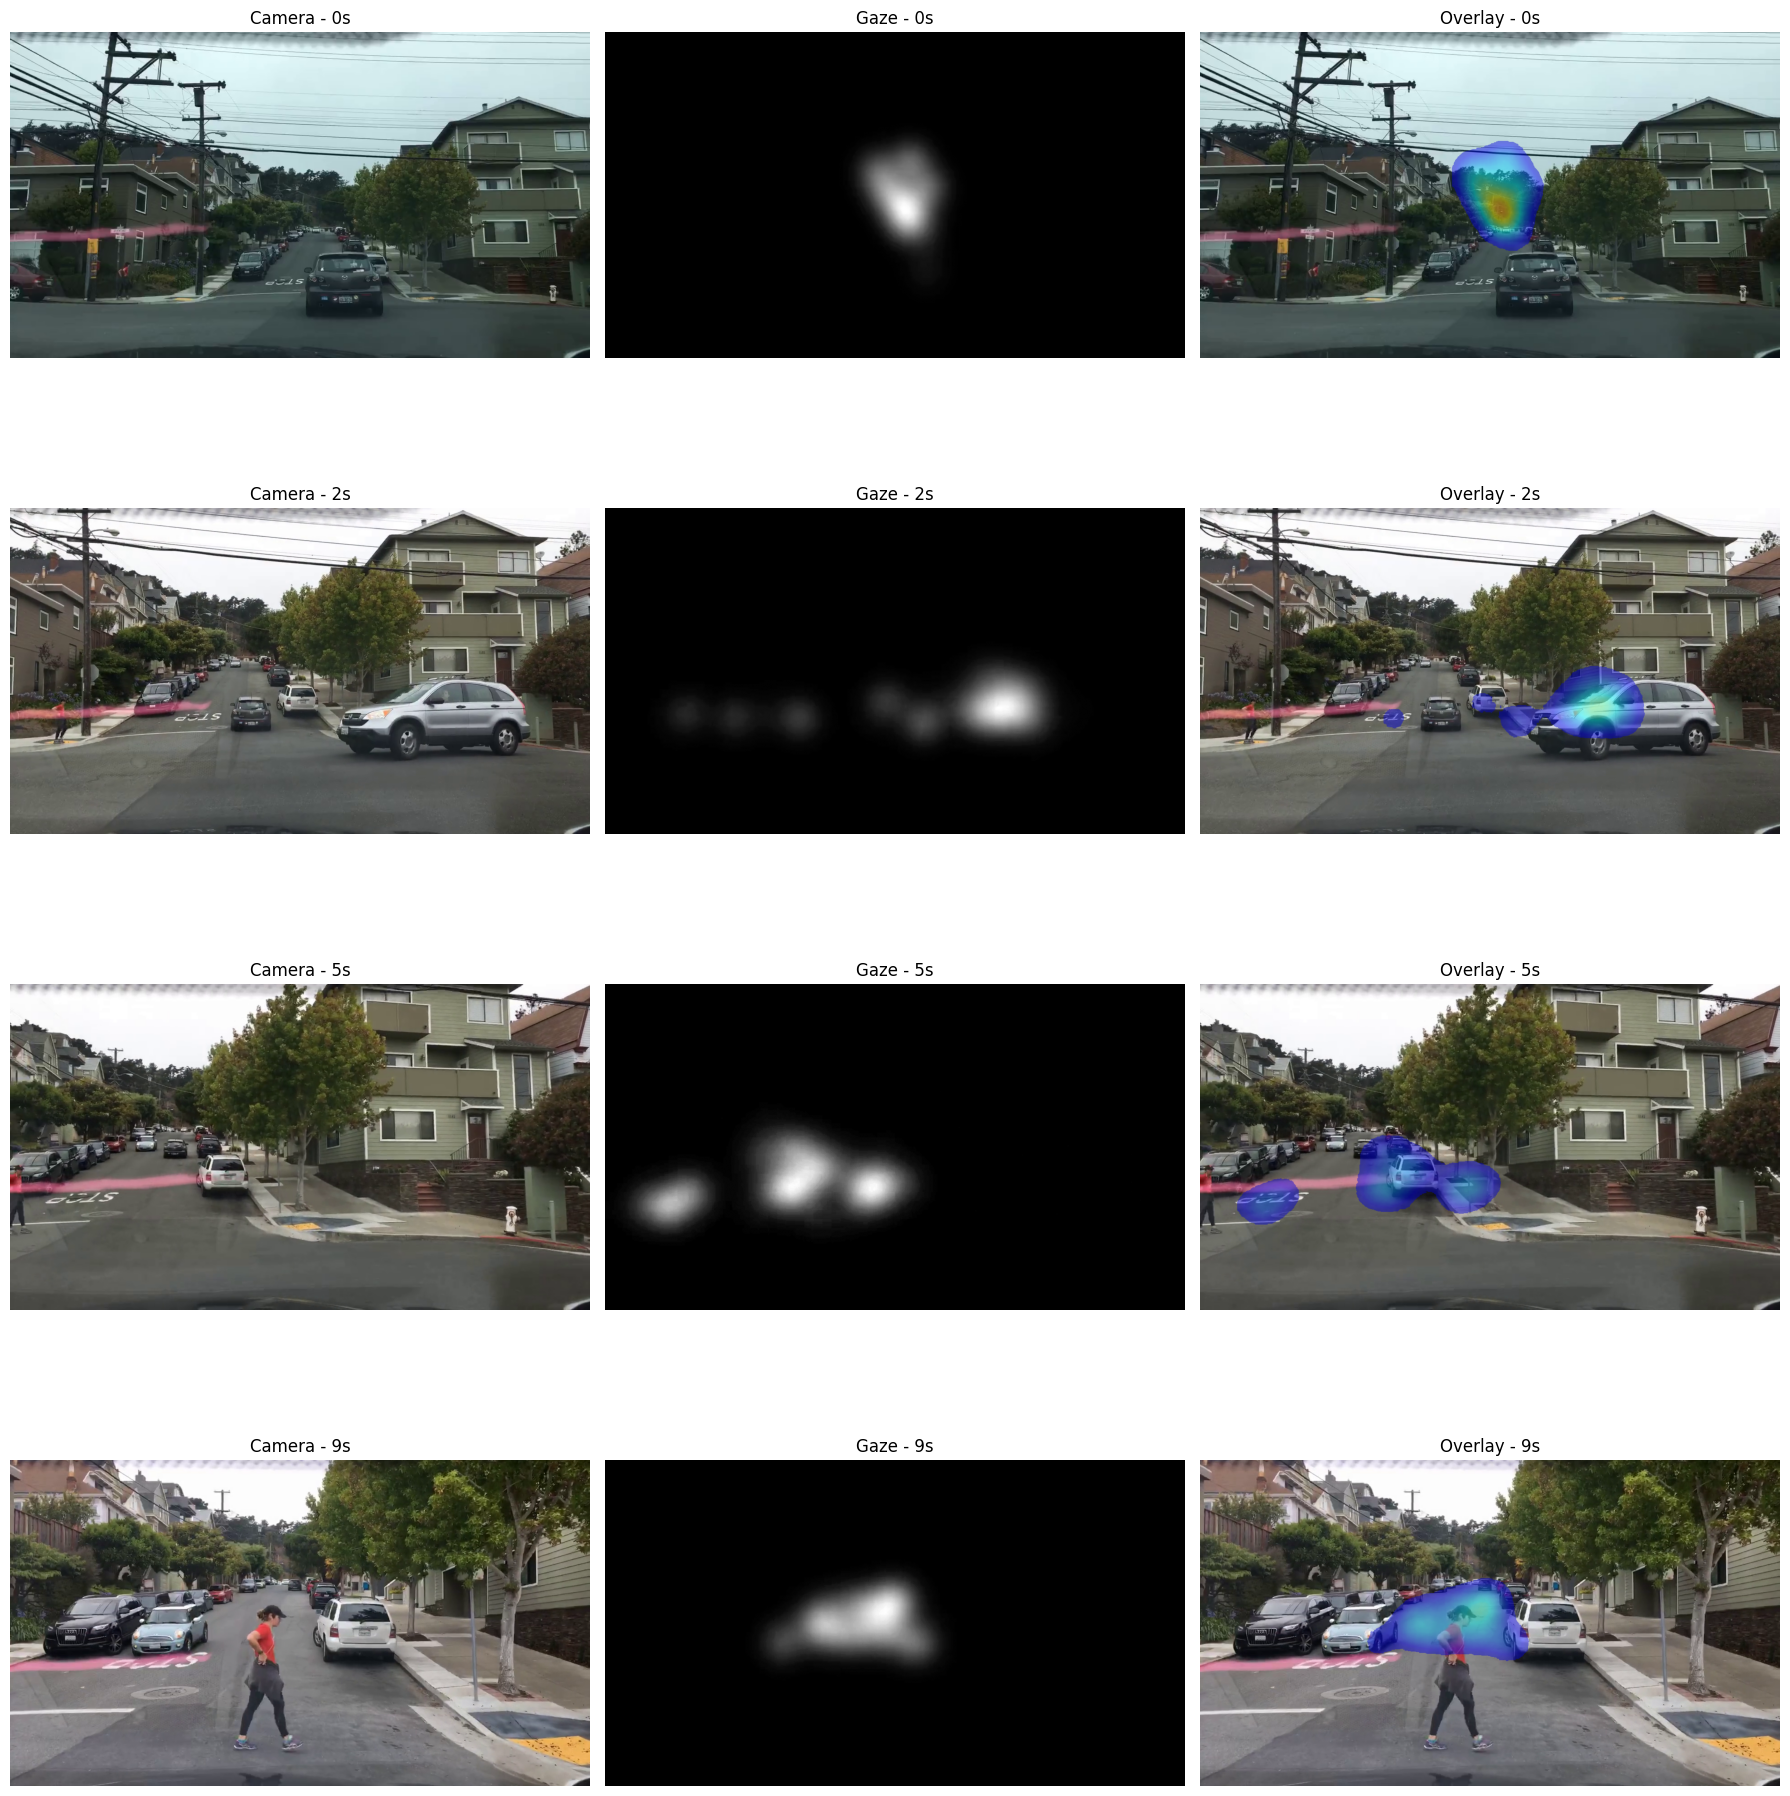

In [17]:

video_id = "2"
split = "training"

camera_path = (
    BDDA_ROOT / split / MODALITIES["camera"] / f"{video_id}.mp4"
)

gaze_path = (
    BDDA_ROOT / split / MODALITIES["gaze"] /
    f"{video_id}_pure_hm.mp4"
)

camera_cap = cv2.VideoCapture(str(camera_path))
gaze_cap = cv2.VideoCapture(str(gaze_path))

timestamps = [0, 2, 5, 9]

fig, axes = plt.subplots(4, 3, figsize=(18, 20))

for i, t in enumerate(timestamps):

    camera_fps = camera_cap.get(cv2.CAP_PROP_FPS)
    gaze_fps = gaze_cap.get(cv2.CAP_PROP_FPS)

    camera_cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        round(t * camera_fps)
    )
    gaze_cap.set(
        cv2.CAP_PROP_POS_FRAMES,
        round(t * gaze_fps)
    )

    ret_cam, camera_frame = camera_cap.read()
    ret_gaze, gaze_frame = gaze_cap.read()

    if not ret_cam or not ret_gaze:
        continue

    camera_frame = cv2.cvtColor(
        camera_frame, cv2.COLOR_BGR2RGB
    )

    gaze_gray = cv2.cvtColor(
        gaze_frame, cv2.COLOR_BGR2GRAY
    )

    # Remove the black bars
    gaze_crop = gaze_gray[96:672, :]

    # Resize to camera dimensions
    gaze_resized = cv2.resize(
        gaze_crop, (1280, 720)
    )

    # Create a colored heatmap
    heatmap = cv2.applyColorMap(
        gaze_resized, cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap, cv2.COLOR_BGR2RGB
    )

    # Overlay only pixels with sufficient gaze intensity
    mask = gaze_resized > 20

    overlay = camera_frame.copy()

    blended = cv2.addWeighted(
        camera_frame, 0.55,
        heatmap, 0.45,
        0
    )

    overlay[mask] = blended[mask]

    axes[i, 0].imshow(camera_frame)
    axes[i, 0].set_title(f"Camera - {t}s")

    axes[i, 1].imshow(gaze_resized, cmap="gray")
    axes[i, 1].set_title(f"Gaze - {t}s")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title(f"Overlay - {t}s")

    for ax in axes[i]:
        ax.axis("off")

camera_cap.release()
gaze_cap.release()

plt.tight_layout()
plt.show()


Section 10 — Charger et examiner un fichier GPS

In [18]:

# Select the GPS file
video_id = "2"
split = "training"

gps_path = (
    BDDA_ROOT / split / MODALITIES["gps"] / f"{video_id}.json"
)

# Load JSON
with open(gps_path, "r", encoding="utf-8") as f:
    gps_metadata = json.load(f)

# Inspect JSON structure
print("Top-level keys:", gps_metadata.keys())

print("\nFile name:", gps_metadata.get("fileName"))
print("Start time:", gps_metadata.get("startTime"))
print("End time:", gps_metadata.get("endTime"))

# Convert GPS locations to DataFrame
gps_df = pd.DataFrame(gps_metadata["locations"])

print("\nNumber of GPS records:", len(gps_df))

display(gps_df.head(10))

print("\nData types:")
print(gps_df.dtypes)


Top-level keys: dict_keys(['locations', 'startTime', 'endTime', 'fileName'])

File name: 2.mp4
Start time: 1468598240500
End time: 1468598250500

Number of GPS records: 10


,course,timestamp,latitude,speed,longitude,accuracy
0,265.548,1468598241000,37.748,2.67,-122.4359,5
1,265.548,1468598242000,37.748,0.84,-122.4359,5
2,265.548,1468598243000,37.748,0.58,-122.4359,5
3,265.548,1468598244000,37.748,2.26,-122.4359,5
4,265.548,1468598245000,37.748,3.87,-122.4360,5
5,265.548,1468598246000,37.748,4.52,-122.4360,5
6,265.548,1468598247000,37.748,1.87,-122.4360,5
7,265.548,1468598248000,37.748,0.36,-122.4360,5
8,265.548,1468598249000,37.748,0.61,-122.4360,5
9,265.548,1468598250000,37.748,0.85,-122.4360,5



Data types:
course       float64
timestamp      int64
latitude     float64
speed        float64
longitude    float64
accuracy       int64
dtype: object


Section 11 — Analyser les timestamps

In [19]:
# Sort by timestamp
gps_df = gps_df.sort_values("timestamp").reset_index(drop=True)

# Calculate time differences in seconds
gps_df["time_interval_sec"] = (
    gps_df["timestamp"].diff() / 1000
)

# Convert timestamps to readable dates
gps_df["datetime"] = pd.to_datetime(
    gps_df["timestamp"],
    unit="ms"
)

# Calculate total GPS recording duration
gps_duration = (
    gps_metadata["endTime"] - gps_metadata["startTime"]
) / 1000

print("GPS records:", len(gps_df))
print("GPS duration:", gps_duration, "seconds")

print("\nGPS sampling interval:")
display(gps_df["time_interval_sec"].describe())

display(gps_df.head(10))

GPS records: 10
GPS duration: 10.0 seconds

GPS sampling interval:


count    9.0
mean     1.0
std      0.0
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: time_interval_sec, dtype: float64

,course,timestamp,latitude,speed,longitude,accuracy,time_interval_sec,datetime
0,265.548,1468598241000,37.748,2.67,-122.4359,5,NaN,2016-07-15 15:57:21
1,265.548,1468598242000,37.748,0.84,-122.4359,5,1.0,2016-07-15 15:57:22
2,265.548,1468598243000,37.748,0.58,-122.4359,5,1.0,2016-07-15 15:57:23
3,265.548,1468598244000,37.748,2.26,-122.4359,5,1.0,2016-07-15 15:57:24
4,265.548,1468598245000,37.748,3.87,-122.4360,5,1.0,2016-07-15 15:57:25
5,265.548,1468598246000,37.748,4.52,-122.4360,5,1.0,2016-07-15 15:57:26
6,265.548,1468598247000,37.748,1.87,-122.4360,5,1.0,2016-07-15 15:57:27
7,265.548,1468598248000,37.748,0.36,-122.4360,5,1.0,2016-07-15 15:57:28
8,265.548,1468598249000,37.748,0.61,-122.4360,5,1.0,2016-07-15 15:57:29
9,265.548,1468598250000,37.748,0.85,-122.4360,5,1.0,2016-07-15 15:57:30


Section 12 — Visualiser la vitesse

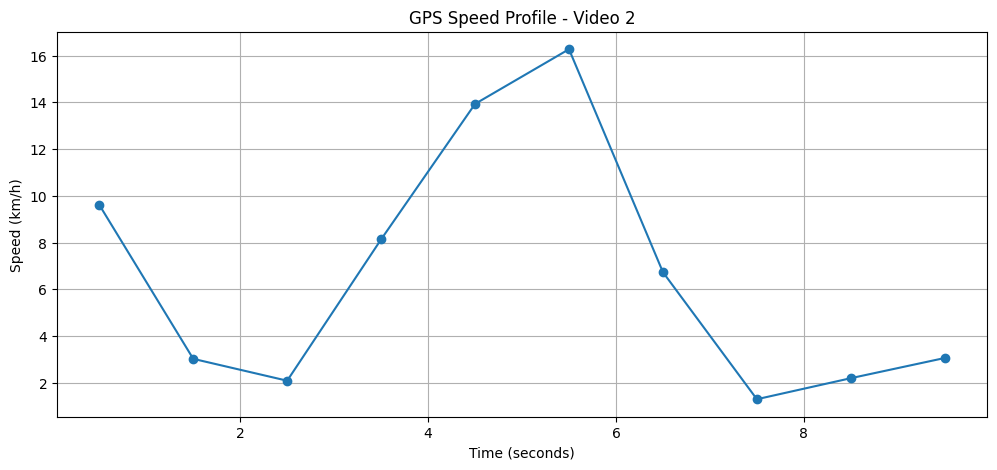

In [20]:
gps_df["speed_kmh"] = gps_df["speed"] * 3.6

plt.figure(figsize=(12, 5))

plt.plot(
    (gps_df["timestamp"] - gps_metadata["startTime"]) / 1000,
    gps_df["speed_kmh"],
    marker="o"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Speed (km/h)")
plt.title(f"GPS Speed Profile - Video {video_id}")
plt.grid(True)
plt.show()

Section 13 — Construire les variables GPS dérivées

In [21]:

# Create a copy to preserve the original GPS data
gps_features_df = gps_df.copy()

# Convert speed from m/s to km/h
gps_features_df["speed_kmh"] = (
    gps_features_df["speed"] * 3.6
)

# Convert heading into sine and cosine
# This avoids the discontinuity between 359° and 0°
gps_features_df["heading_sin"] = np.sin(
    np.deg2rad(gps_features_df["course"])
)

gps_features_df["heading_cos"] = np.cos(
    np.deg2rad(gps_features_df["course"])
)

# Time relative to video start
gps_features_df["time_seconds"] = (
    gps_features_df["timestamp"]
    - gps_metadata["startTime"]
) / 1000

# Estimate longitudinal acceleration
gps_features_df["acceleration"] = (
    gps_features_df["speed"].diff()
    / gps_features_df["time_interval_sec"]
)

display(
    gps_features_df[
        [
            "time_seconds",
            "speed",
            "speed_kmh",
            "course",
            "heading_sin",
            "heading_cos",
            "acceleration",
            "accuracy"
        ]
    ]
)


,time_seconds,speed,speed_kmh,course,heading_sin,heading_cos,acceleration,accuracy
0,0.5,2.67,9.612,265.548,-0.996983,-0.077624,NaN,5
1,1.5,0.84,3.024,265.548,-0.996983,-0.077624,-1.83,5
2,2.5,0.58,2.088,265.548,-0.996983,-0.077624,-0.26,5
3,3.5,2.26,8.136,265.548,-0.996983,-0.077624,1.68,5
4,4.5,3.87,13.932,265.548,-0.996983,-0.077624,1.61,5
5,5.5,4.52,16.272,265.548,-0.996983,-0.077624,0.65,5
6,6.5,1.87,6.732,265.548,-0.996983,-0.077624,-2.65,5
7,7.5,0.36,1.296,265.548,-0.996983,-0.077624,-1.51,5
8,8.5,0.61,2.196,265.548,-0.996983,-0.077624,0.25,5
9,9.5,0.85,3.060,265.548,-0.996983,-0.077624,0.24,5


Cellule 14 — Visualiser la trajectoire GPS

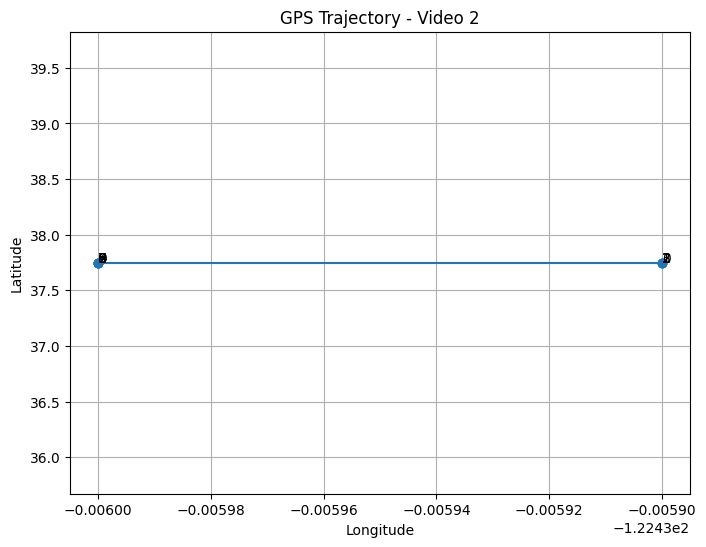

In [22]:

plt.figure(figsize=(8, 6))

plt.plot(
    gps_features_df["longitude"],
    gps_features_df["latitude"],
    marker="o"
)

for i, row in gps_features_df.iterrows():
    plt.annotate(
        str(i),
        (row["longitude"], row["latitude"])
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"GPS Trajectory - Video {video_id}")
plt.grid(True)
plt.show()


In [23]:

def inspect_gps_metadata(split, video_id):
    gps_path = (
        BDDA_ROOT / split / MODALITIES["gps"] /
        f"{video_id}.json"
    )

    with open(gps_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    df = pd.DataFrame(metadata["locations"])
    df = df.sort_values("timestamp")

    intervals = df["timestamp"].diff() / 1000

    return {
        "split": split,
        "video_id": video_id,
        "gps_records": len(df),
        "duration_sec": (
            metadata["endTime"] - metadata["startTime"]
        ) / 1000,
        "mean_interval_sec": intervals.mean(),
        "min_interval_sec": intervals.min(),
        "max_interval_sec": intervals.max(),
        "first_offset_sec": (
            df["timestamp"].iloc[0] - metadata["startTime"]
        ) / 1000,
        "last_offset_sec": (
            df["timestamp"].iloc[-1] - metadata["startTime"]
        ) / 1000
    }


# Inspect several videos, including different camera FPS cases
sample_ids = ["2", "5", "10", "17"]

gps_inspection = pd.DataFrame([
    inspect_gps_metadata("training", vid)
    for vid in sample_ids
])

display(gps_inspection)


,split,video_id,gps_records,duration_sec,mean_interval_sec,min_interval_sec,max_interval_sec,first_offset_sec,last_offset_sec
0,training,2,10,10.0,1.0,1.0,1.0,0.5,9.5
1,training,5,10,10.0,1.0,1.0,1.0,0.5,9.5
2,training,10,10,10.0,1.0,1.0,1.0,0.5,9.5
3,training,17,10,10.0,1.0,1.0,1.0,0.5,9.5


In [24]:

from pathlib import Path
import cv2
import json
import pandas as pd
import numpy as np

split = "training"
video_id = "2"

camera_path = BDDA_ROOT / split / "camera_videos" / f"{video_id}.mp4"
gaze_path = BDDA_ROOT / split / "gazemap_videos" / f"{video_id}_pure_hm.mp4"
gps_path = BDDA_ROOT / split / "gps_jsons" / f"{video_id}.json"

# Read video metadata
camera = cv2.VideoCapture(str(camera_path))
gaze = cv2.VideoCapture(str(gaze_path))

camera_fps = camera.get(cv2.CAP_PROP_FPS)
gaze_fps = gaze.get(cv2.CAP_PROP_FPS)

camera_frames = int(camera.get(cv2.CAP_PROP_FRAME_COUNT))
gaze_frames = int(gaze.get(cv2.CAP_PROP_FRAME_COUNT))

camera.release()
gaze.release()

# Read GPS data
with open(gps_path, "r") as f:
    gps_metadata = json.load(f)

gps_df = pd.DataFrame(gps_metadata["locations"])

# Convert GPS timestamps into seconds relative to video start
gps_df["time_seconds"] = (
    gps_df["timestamp"] - gps_metadata["startTime"]
) / 1000

# Build common timeline using GPS timestamps
timeline = []

for _, gps_row in gps_df.iterrows():
    t = gps_row["time_seconds"]

    camera_idx = round(t * camera_fps)
    gaze_idx = round(t * gaze_fps)

    timeline.append({
        "time_seconds": t,
        "camera_frame": camera_idx,
        "gaze_frame": gaze_idx,
        "gps_speed_m_s": gps_row["speed"],
        "gps_speed_kmh": gps_row["speed"] * 3.6,
        "gps_course": gps_row["course"],
        "gps_latitude": gps_row["latitude"],
        "gps_longitude": gps_row["longitude"],
        "gps_accuracy": gps_row["accuracy"],
        "camera_frame_valid": camera_idx < camera_frames,
        "gaze_frame_valid": gaze_idx < gaze_frames
    })

timeline_df = pd.DataFrame(timeline)

display(timeline_df)


,time_seconds,camera_frame,gaze_frame,gps_speed_m_s,gps_speed_kmh,gps_course,gps_latitude,gps_longitude,gps_accuracy,camera_frame_valid,gaze_frame_valid
0,0.5,15,14,2.67,9.612,265.548,37.748,-122.4359,5.0,True,True
1,1.5,45,44,0.84,3.024,265.548,37.748,-122.4359,5.0,True,True
2,2.5,75,72,0.58,2.088,265.548,37.748,-122.4359,5.0,True,True
3,3.5,105,102,2.26,8.136,265.548,37.748,-122.4359,5.0,True,True
4,4.5,135,130,3.87,13.932,265.548,37.748,-122.4360,5.0,True,True
5,5.5,165,160,4.52,16.272,265.548,37.748,-122.4360,5.0,True,True
6,6.5,195,188,1.87,6.732,265.548,37.748,-122.4360,5.0,True,True
7,7.5,225,218,0.36,1.296,265.548,37.748,-122.4360,5.0,True,True
8,8.5,255,246,0.61,2.196,265.548,37.748,-122.4360,5.0,True,True
9,9.5,285,276,0.85,3.060,265.548,37.748,-122.4360,5.0,True,True
